In [ ]:
# ================================================================
# PHASE 4B — CELL 1
# SETUP
# ================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from scipy.stats import (
    mannwhitneyu,
    spearmanr
)


print("=" * 80)
print("PHASE 4B — CONFIDENCE & UNCERTAINTY ANALYSIS")
print("=" * 80)

print("""
Purpose:
Evaluate whether confidence scores from the frozen Phase 3
classifier contain useful information about prediction reliability.

Protocol:
• Frozen Phase 3D predictions only
• No retraining
• No classifier modification
• No probability calibration using the evaluation set
• No confidence-threshold optimization using the evaluation set
• Confidence analyses are descriptive/exploratory
• Probabilities are treated as model confidence scores,
  NOT calibrated probabilities of correctness
""")

Mounted at /content/drive
PHASE 4B — CONFIDENCE & UNCERTAINTY ANALYSIS

Purpose:
Evaluate whether confidence scores from the frozen Phase 3
classifier contain useful information about prediction reliability.

Protocol:
• Frozen Phase 3D predictions only
• No retraining
• No classifier modification
• No probability calibration using the evaluation set
• No confidence-threshold optimization using the evaluation set
• Confidence analyses are descriptive/exploratory
• Probabilities are treated as model confidence scores,
  NOT calibrated probabilities of correctness



In [ ]:
# ================================================================
# PHASE 4B — CELL 2
# PATHS
# ================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE3D_DIR = (
    PROJECT_ROOT
    / "phase3_classification"
    / "phase3D_final_evaluation"
)

PHASE4_ROOT = (
    PROJECT_ROOT
    / "phase4_robustness"
)

PHASE4A_DIR = (
    PHASE4_ROOT
    / "phase4A_error_propagation"
)

PHASE4B_DIR = (
    PHASE4_ROOT
    / "phase4B_confidence_uncertainty"
)

PHASE4B_TABLES_DIR = (
    PHASE4B_DIR
    / "tables"
)

PHASE4B_FIGURES_DIR = (
    PHASE4B_DIR
    / "figures"
)

PHASE4B_CONFIGS_DIR = (
    PHASE4B_DIR
    / "configs"
)


for directory in [
    PHASE4B_DIR,
    PHASE4B_TABLES_DIR,
    PHASE4B_FIGURES_DIR,
    PHASE4B_CONFIGS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


assert PHASE3D_DIR.exists()
assert PHASE4A_DIR.exists()


print("Phase 3D:")
print(PHASE3D_DIR)

print("\nFrozen Phase 4A:")
print(PHASE4A_DIR)

print("\nPhase 4B:")
print(PHASE4B_DIR)

print(
    "\n✓ Phase 4B output structure ready."
)

Phase 3D:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3D_final_evaluation

Frozen Phase 4A:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation

Phase 4B:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty

✓ Phase 4B output structure ready.


In [ ]:
# ================================================================
# PHASE 4B — CELL 3
# VERIFY PREVIOUS PHASE COMPLETION
# ================================================================

PHASE4A_COMPLETION_PATH = (
    PHASE4A_DIR
    / "PHASE4A_COMPLETE.json"
)


assert PHASE4A_COMPLETION_PATH.exists(), (
    "Phase 4A completion marker not found."
)


with open(
    PHASE4A_COMPLETION_PATH,
    "r"
) as file:

    phase4A_completion = json.load(file)


print("=" * 80)
print("PHASE 4A STATUS")
print("=" * 80)

print(
    "\nStatus:",
    phase4A_completion.get("status")
)

print(
    "Patients:",
    phase4A_completion.get("n_patients")
)

print(
    "Next phase:",
    phase4A_completion.get("next_phase")
)


assert (
    phase4A_completion.get("status")
    == "COMPLETE_AND_FROZEN"
)


print(
    "\n✓ Phase 4A confirmed frozen."
)

PHASE 4A STATUS

Status: COMPLETE_AND_FROZEN
Patients: 50
Next phase: Phase 4B — Confidence and Uncertainty Analysis

✓ Phase 4A confirmed frozen.


In [ ]:
# ================================================================
# PHASE 4B — CELL 4
# LOAD FROZEN CLASSIFIER OUTPUTS
# ================================================================

PHASE3D_PREDICTIONS_PATH = (
    PHASE3D_DIR
    / "tables"
    / "phase3D_final_patient_predictions.csv"
)


assert PHASE3D_PREDICTIONS_PATH.exists()


phase4B_df = pd.read_csv(
    PHASE3D_PREDICTIONS_PATH
)


required_columns = [

    "patient_id",

    "reference_EF_pct",
    "reference_EF_class",

    "PRED_EF_pct",

    "learned_prediction",
    "correct",

    "prob_Higher_EF",
    "prob_Intermediate_EF",
    "prob_Lower_EF",

    "absolute_EF_error_pp"
]


missing_columns = [
    column
    for column in required_columns
    if column not in phase4B_df.columns
]


assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)


assert len(
    phase4B_df
) == 50


assert phase4B_df[
    "patient_id"
].nunique() == 50


print("=" * 80)
print("FROZEN PHASE 3D PREDICTIONS LOADED")
print("=" * 80)

print(
    "\nShape:",
    phase4B_df.shape
)

print(
    "Patients:",
    phase4B_df[
        "patient_id"
    ].nunique()
)

print(
    "Correct:",
    int(
        phase4B_df[
            "correct"
        ].astype(bool).sum()
    )
)

print(
    "Incorrect:",
    int(
        (
            ~phase4B_df[
                "correct"
            ].astype(bool)
        ).sum()
    )
)


print(
    "\n✓ Frozen classifier outputs ready."
)

FROZEN PHASE 3D PREDICTIONS LOADED

Shape: (50, 17)
Patients: 50
Correct: 35
Incorrect: 15

✓ Frozen classifier outputs ready.


In [ ]:
# ================================================================
# PHASE 4B — CELL 5
# DERIVE CONFIDENCE / UNCERTAINTY VARIABLES
# ================================================================

phase4B_df = phase4B_df.copy()


probability_columns = [

    "prob_Higher_EF",
    "prob_Intermediate_EF",
    "prob_Lower_EF"
]


probability_matrix = phase4B_df[
    probability_columns
].to_numpy(
    dtype=float
)


# ---------------------------------------------------------------
# BASIC PROBABILITY SANITY CHECKS
# ---------------------------------------------------------------

assert np.all(
    probability_matrix >= 0
)

assert np.all(
    probability_matrix <= 1
)


probability_sums = (
    probability_matrix.sum(
        axis=1
    )
)


max_probability_sum_error = np.max(
    np.abs(
        probability_sums - 1.0
    )
)


print(
    "Maximum probability-sum deviation from 1:",
    max_probability_sum_error
)


assert max_probability_sum_error < 1e-6


# ---------------------------------------------------------------
# MAXIMUM MODEL CONFIDENCE
# ---------------------------------------------------------------

phase4B_df[
    "model_confidence"
] = np.max(
    probability_matrix,
    axis=1
)


# ---------------------------------------------------------------
# CONFIDENCE MARGIN
# ---------------------------------------------------------------

sorted_probabilities = np.sort(
    probability_matrix,
    axis=1
)


phase4B_df[
    "confidence_margin"
] = (
    sorted_probabilities[:, -1]
    -
    sorted_probabilities[:, -2]
)


# ---------------------------------------------------------------
# PREDICTIVE ENTROPY
# ---------------------------------------------------------------

safe_probabilities = np.clip(
    probability_matrix,
    1e-12,
    1.0
)


entropy = -np.sum(
    safe_probabilities
    * np.log(
        safe_probabilities
    ),
    axis=1
)


phase4B_df[
    "predictive_entropy"
] = entropy


# Normalize entropy to 0–1 for easier interpretation.
# Maximum entropy for 3 classes = log(3).

phase4B_df[
    "normalized_entropy"
] = (
    phase4B_df[
        "predictive_entropy"
    ]
    /
    np.log(3)
)


# ---------------------------------------------------------------
# CLASSIFICATION ERROR INDICATOR
# ---------------------------------------------------------------

phase4B_df[
    "classification_error"
] = (
    ~phase4B_df[
        "correct"
    ].astype(bool)
).astype(int)


print("\n" + "=" * 80)
print("CONFIDENCE / UNCERTAINTY VARIABLES")
print("=" * 80)


summary = phase4B_df[[
    "model_confidence",
    "confidence_margin",
    "normalized_entropy"
]].describe()


display(
    summary.round(4)
)


print(
    "\nMean model confidence:",
    f"{phase4B_df['model_confidence'].mean():.4f}"
)

print(
    "Mean confidence margin:",
    f"{phase4B_df['confidence_margin'].mean():.4f}"
)

print(
    "Mean normalized entropy:",
    f"{phase4B_df['normalized_entropy'].mean():.4f}"
)


print(
    "\nInterpretation:"
)

print(
    "• Higher model confidence = stronger preference for one class."
)

print(
    "• Higher confidence margin = greater separation between "
    "the top two classes."
)

print(
    "• Higher normalized entropy = greater uncertainty."
)

print(
    "\n✓ Confidence and uncertainty variables derived."
)

Maximum probability-sum deviation from 1: 3.3306690738754696e-16

CONFIDENCE / UNCERTAINTY VARIABLES


,model_confidence,confidence_margin,normalized_entropy
count,50.0000,50.0000,50.0000
mean,0.7079,0.4605,0.5954
std,0.1360,0.2363,0.2194
min,0.4694,0.0118,0.0293
25%,0.5877,0.3162,0.5061
50%,0.6937,0.4090,0.6229
75%,0.7885,0.5868,0.7171
max,0.9949,0.9897,0.9026



Mean model confidence: 0.7079
Mean confidence margin: 0.4605
Mean normalized entropy: 0.5954

Interpretation:
• Higher model confidence = stronger preference for one class.
• Higher confidence margin = greater separation between the top two classes.
• Higher normalized entropy = greater uncertainty.

✓ Confidence and uncertainty variables derived.


In [ ]:
# ================================================================
# PHASE 4B — CELL 6
# VERIFY CLASS-PROBABILITY CONSISTENCY
# ================================================================

class_order = np.array([
    "Higher_EF",
    "Intermediate_EF",
    "Lower_EF"
])


highest_probability_index = np.argmax(
    probability_matrix,
    axis=1
)


highest_probability_class = (
    class_order[
        highest_probability_index
    ]
)


phase4B_df[
    "highest_probability_class"
] = highest_probability_class


class_probability_match = (
    phase4B_df[
        "highest_probability_class"
    ].to_numpy()
    ==
    phase4B_df[
        "learned_prediction"
    ].to_numpy()
)


print("=" * 80)
print("CLASS / PROBABILITY CONSISTENCY")
print("=" * 80)

print(
    "\nMatching predictions:",
    int(
        class_probability_match.sum()
    ),
    "/",
    len(
        class_probability_match
    )
)


if not np.all(
    class_probability_match
):

    print(
        "\nMismatching rows:"
    )

    display(
        phase4B_df.loc[
            ~class_probability_match,
            [
                "patient_id",
                "learned_prediction",
                "highest_probability_class",
                *probability_columns
            ]
        ]
    )


assert np.all(
    class_probability_match
), (
    "Stored predicted class does not always match "
    "the maximum class score."
)


print(
    "\n✓ All frozen predictions match the highest class score."
)

CLASS / PROBABILITY CONSISTENCY

Matching predictions: 50 / 50

✓ All frozen predictions match the highest class score.


In [ ]:
# ================================================================
# PHASE 4B — CELL 7
# CONFIDENCE: CORRECT VS INCORRECT
# ================================================================

confidence_variables = {

    "Model confidence":
        "model_confidence",

    "Confidence margin":
        "confidence_margin",

    "Normalized entropy":
        "normalized_entropy"
}


correct_df = phase4B_df[
    phase4B_df[
        "classification_error"
    ] == 0
]


incorrect_df = phase4B_df[
    phase4B_df[
        "classification_error"
    ] == 1
]


confidence_comparison_results = []


for display_name, column in confidence_variables.items():

    correct_values = (
        correct_df[
            column
        ].dropna()
    )

    incorrect_values = (
        incorrect_df[
            column
        ].dropna()
    )


    statistic, p_value = mannwhitneyu(
        correct_values,
        incorrect_values,
        alternative="two-sided"
    )


    confidence_comparison_results.append({

        "metric":
            display_name,

        "correct_n":
            len(correct_values),

        "correct_median":
            correct_values.median(),

        "incorrect_n":
            len(incorrect_values),

        "incorrect_median":
            incorrect_values.median(),

        "incorrect_minus_correct_median":
            (
                incorrect_values.median()
                -
                correct_values.median()
            ),

        "mann_whitney_U":
            statistic,

        "p_value":
            p_value
    })


phase4B_confidence_comparison_df = pd.DataFrame(
    confidence_comparison_results
)


print("=" * 80)
print("CONFIDENCE — CORRECT VS INCORRECT")
print("=" * 80)

display(
    phase4B_confidence_comparison_df.round(4)
)


print(
    "\nExpected direction if confidence is informative:"
)

print(
    "• Correct cases → higher model confidence"
)

print(
    "• Correct cases → larger confidence margin"
)

print(
    "• Incorrect cases → higher entropy"
)

print(
    "\nThese are exploratory comparisons on the frozen "
    "evaluation set."
)

CONFIDENCE — CORRECT VS INCORRECT


,metric,correct_n,correct_median,incorrect_n,incorrect_median,incorrect_minus_correct_median,mann_whitney_U,p_value
0,Model confidence,35,0.7082,15,0.6613,-0.0469,349.0,0.0687
1,Confidence margin,35,0.4280,15,0.3495,-0.0784,341.0,0.0987
2,Normalized entropy,35,0.5939,15,0.6684,0.0745,178.0,0.0754



Expected direction if confidence is informative:
• Correct cases → higher model confidence
• Correct cases → larger confidence margin
• Incorrect cases → higher entropy

These are exploratory comparisons on the frozen evaluation set.


In [ ]:
# ================================================================
# PHASE 4B — CELL 8
# CONFIDENCE VS END-TO-END EF ERROR
# ================================================================

confidence_error_tests = [

    (
        "Model confidence",
        "model_confidence"
    ),

    (
        "Confidence margin",
        "confidence_margin"
    ),

    (
        "Normalized entropy",
        "normalized_entropy"
    )
]


confidence_error_results = []


for display_name, column in confidence_error_tests:

    rho, p_value = spearmanr(

        phase4B_df[
            column
        ],

        phase4B_df[
            "absolute_EF_error_pp"
        ]
    )


    confidence_error_results.append({

        "confidence_metric":
            display_name,

        "outcome":
            "Absolute end-to-end EF error (pp)",

        "spearman_rho":
            rho,

        "p_value":
            p_value
    })


phase4B_confidence_error_df = pd.DataFrame(
    confidence_error_results
)


print("=" * 80)
print("CONFIDENCE VS END-TO-END EF ERROR")
print("=" * 80)


display(
    phase4B_confidence_error_df.round({
        "spearman_rho": 4,
        "p_value": 6
    })
)


print(
    "\nIf confidence tracks quantitative reliability, "
    "we would expect:"
)

print(
    "• confidence / margin → negative association with EF error"
)

print(
    "• entropy → positive association with EF error"
)

print(
    "\nNo direction will be assumed unless supported by "
    "the observed results."
)

CONFIDENCE VS END-TO-END EF ERROR


,confidence_metric,outcome,spearman_rho,p_value
0,Model confidence,Absolute end-to-end EF error (pp),0.0400,0.782702
1,Confidence margin,Absolute end-to-end EF error (pp),0.0830,0.566496
2,Normalized entropy,Absolute end-to-end EF error (pp),-0.0753,0.603053



If confidence tracks quantitative reliability, we would expect:
• confidence / margin → negative association with EF error
• entropy → positive association with EF error

No direction will be assumed unless supported by the observed results.


In [ ]:
# ================================================================
# PHASE 4B — CELL 9
# CONFIDENCE BY REFERENCE EF CLASS
# ================================================================

class_order_display = [
    "Lower_EF",
    "Intermediate_EF",
    "Higher_EF"
]


class_confidence_summary = (
    phase4B_df
    .groupby(
        "reference_EF_class"
    )
    .agg(

        n=(
            "patient_id",
            "count"
        ),

        correct=(
            "correct",
            "sum"
        ),

        median_confidence=(
            "model_confidence",
            "median"
        ),

        mean_confidence=(
            "model_confidence",
            "mean"
        ),

        median_margin=(
            "confidence_margin",
            "median"
        ),

        median_entropy=(
            "normalized_entropy",
            "median"
        )
    )
    .reindex(
        class_order_display
    )
    .reset_index()
)


class_confidence_summary[
    "accuracy_pct"
] = (
    class_confidence_summary[
        "correct"
    ]
    /
    class_confidence_summary[
        "n"
    ]
    * 100
)


print("=" * 80)
print("CONFIDENCE BY REFERENCE EF CLASS")
print("=" * 80)

display(
    class_confidence_summary.round(4)
)


print(
    "\nNOTE:"
)

print(
    "These are descriptive class-level summaries."
)

print(
    "No class-specific confidence thresholds are being selected."
)

CONFIDENCE BY REFERENCE EF CLASS


,reference_EF_class,n,correct,median_confidence,mean_confidence,median_margin,median_entropy,accuracy_pct
0,Lower_EF,16,13,0.7231,0.7475,0.4567,0.5772,81.2500
1,Intermediate_EF,14,5,0.6360,0.6448,0.3529,0.6795,35.7143
2,Higher_EF,20,17,0.7180,0.7204,0.4549,0.6039,85.0000



NOTE:
These are descriptive class-level summaries.
No class-specific confidence thresholds are being selected.


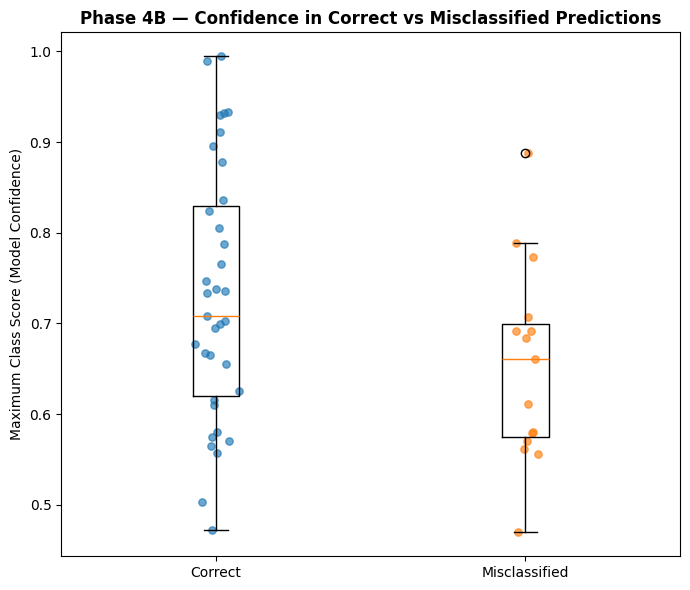

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/figures/phase4B_confidence_correct_vs_incorrect.png


In [ ]:
# ================================================================
# PHASE 4B — CELL 10
# CONFIDENCE — CORRECT VS INCORRECT FIGURE
# ================================================================

correct_confidence = (
    phase4B_df.loc[
        phase4B_df["classification_error"] == 0,
        "model_confidence"
    ].to_numpy()
)

incorrect_confidence = (
    phase4B_df.loc[
        phase4B_df["classification_error"] == 1,
        "model_confidence"
    ].to_numpy()
)


fig, ax = plt.subplots(
    figsize=(7, 6)
)


ax.boxplot(
    [
        correct_confidence,
        incorrect_confidence
    ],
    tick_labels=[
        "Correct",
        "Misclassified"
    ],
    showfliers=True
)


# Add individual observations
rng = np.random.default_rng(42)

for position, values in enumerate(
    [
        correct_confidence,
        incorrect_confidence
    ],
    start=1
):

    jitter = rng.normal(
        position,
        0.035,
        size=len(values)
    )

    ax.scatter(
        jitter,
        values,
        alpha=0.65,
        s=28
    )


ax.set_ylabel(
    "Maximum Class Score (Model Confidence)"
)

ax.set_title(
    "Phase 4B — Confidence in Correct vs Misclassified Predictions",
    fontweight="bold"
)


plt.tight_layout()


CONFIDENCE_CORRECTNESS_FIGURE_PATH = (
    PHASE4B_FIGURES_DIR
    / "phase4B_confidence_correct_vs_incorrect.png"
)


plt.savefig(
    CONFIDENCE_CORRECTNESS_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    CONFIDENCE_CORRECTNESS_FIGURE_PATH
)

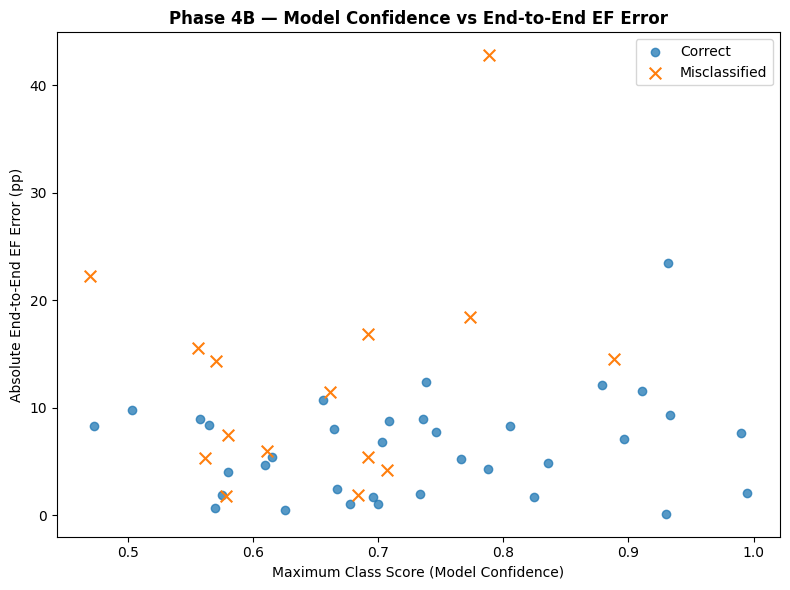

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/figures/phase4B_confidence_vs_EF_error.png


In [ ]:
# ================================================================
# PHASE 4B — CELL 11
# CONFIDENCE VS END-TO-END EF ERROR FIGURE
# ================================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


correct_cases = phase4B_df[
    phase4B_df[
        "classification_error"
    ] == 0
]

incorrect_cases = phase4B_df[
    phase4B_df[
        "classification_error"
    ] == 1
]


ax.scatter(
    correct_cases[
        "model_confidence"
    ],
    correct_cases[
        "absolute_EF_error_pp"
    ],
    alpha=0.75,
    label="Correct"
)


ax.scatter(
    incorrect_cases[
        "model_confidence"
    ],
    incorrect_cases[
        "absolute_EF_error_pp"
    ],
    marker="x",
    s=70,
    label="Misclassified"
)


ax.set_xlabel(
    "Maximum Class Score (Model Confidence)"
)

ax.set_ylabel(
    "Absolute End-to-End EF Error (pp)"
)

ax.set_title(
    "Phase 4B — Model Confidence vs End-to-End EF Error",
    fontweight="bold"
)


ax.legend()

plt.tight_layout()


CONFIDENCE_EF_FIGURE_PATH = (
    PHASE4B_FIGURES_DIR
    / "phase4B_confidence_vs_EF_error.png"
)


plt.savefig(
    CONFIDENCE_EF_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    CONFIDENCE_EF_FIGURE_PATH
)

In [ ]:
# ================================================================
# PHASE 4B — CELL 12
# HIGH-CONFIDENCE MISCLASSIFICATION AUDIT
# ================================================================

misclassified_confidence_df = (

    phase4B_df[
        phase4B_df[
            "classification_error"
        ] == 1
    ]

    .copy()

    .sort_values(
        "model_confidence",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


misclassified_confidence_df.insert(
    0,
    "misclassification_confidence_rank",
    np.arange(
        1,
        len(misclassified_confidence_df) + 1
    )
)


audit_columns = [

    "misclassification_confidence_rank",

    "patient_id",

    "reference_EF_pct",
    "reference_EF_class",

    "PRED_EF_pct",
    "learned_prediction",

    "absolute_EF_error_pp",

    "model_confidence",
    "confidence_margin",
    "normalized_entropy",

    "prob_Lower_EF",
    "prob_Intermediate_EF",
    "prob_Higher_EF"
]


print("=" * 80)
print("MISCLASSIFICATIONS RANKED BY MODEL CONFIDENCE")
print("=" * 80)


display(
    misclassified_confidence_df[
        audit_columns
    ].round(4)
)


HIGH_CONFIDENCE_ERROR_PATH = (
    PHASE4B_TABLES_DIR
    / "phase4B_misclassifications_ranked_by_confidence.csv"
)


misclassified_confidence_df[
    audit_columns
].to_csv(
    HIGH_CONFIDENCE_ERROR_PATH,
    index=False
)


print(
    "\nSaved:",
    HIGH_CONFIDENCE_ERROR_PATH
)

MISCLASSIFICATIONS RANKED BY MODEL CONFIDENCE


,misclassification_confidence_rank,patient_id,reference_EF_pct,reference_EF_class,PRED_EF_pct,learned_prediction,absolute_EF_error_pp,model_confidence,confidence_margin,normalized_entropy,prob_Lower_EF,prob_Intermediate_EF,prob_Higher_EF
0,1,patient0358,44.0,Intermediate_EF,29.4360,Lower_EF,14.5640,0.8882,0.7776,0.3250,0.8882,0.1106,0.0012
1,2,patient0217,19.0,Lower_EF,61.7946,Higher_EF,42.7946,0.7888,0.5875,0.5055,0.0099,0.2013,0.7888
2,3,patient0465,45.0,Intermediate_EF,63.4368,Higher_EF,18.4368,0.7731,0.5594,0.5332,0.0132,0.2137,0.7731
3,4,patient0389,44.0,Intermediate_EF,39.8103,Lower_EF,4.1897,0.7073,0.4254,0.5922,0.7073,0.2819,0.0107
4,5,patient0303,43.0,Intermediate_EF,37.5657,Lower_EF,5.4343,0.6920,0.3971,0.6117,0.6920,0.2948,0.0132
5,6,patient0175,45.0,Intermediate_EF,61.8192,Higher_EF,16.8192,0.6918,0.4083,0.6406,0.0247,0.2835,0.6918
6,7,patient0487,41.0,Intermediate_EF,42.8643,Lower_EF,1.8643,0.6837,0.3828,0.6243,0.6837,0.3009,0.0155
7,8,patient0380,48.0,Intermediate_EF,59.4571,Higher_EF,11.4571,0.6613,0.3495,0.6684,0.0270,0.3117,0.6613
8,9,patient0378,49.0,Intermediate_EF,43.0215,Lower_EF,5.9785,0.6107,0.2454,0.6906,0.6107,0.3653,0.0240
9,10,patient0302,49.0,Intermediate_EF,41.5123,Lower_EF,7.4877,0.5803,0.1865,0.7078,0.5803,0.3938,0.0259



Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/tables/phase4B_misclassifications_ranked_by_confidence.csv


In [ ]:
# ================================================================
# PHASE 4B — CELL 13
# LOW-CONFIDENCE CORRECT-PREDICTION AUDIT
# ================================================================

correct_confidence_ranked_df = (

    phase4B_df[
        phase4B_df[
            "classification_error"
        ] == 0
    ]

    .copy()

    .sort_values(
        "model_confidence",
        ascending=True
    )

    .reset_index(
        drop=True
    )
)


correct_confidence_ranked_df.insert(
    0,
    "low_confidence_rank",
    np.arange(
        1,
        len(correct_confidence_ranked_df) + 1
    )
)


correct_audit_columns = [

    "low_confidence_rank",

    "patient_id",

    "reference_EF_pct",
    "reference_EF_class",

    "PRED_EF_pct",
    "learned_prediction",

    "absolute_EF_error_pp",

    "model_confidence",
    "confidence_margin",
    "normalized_entropy"
]


print("=" * 80)
print("10 LOWEST-CONFIDENCE CORRECT PREDICTIONS")
print("=" * 80)


display(
    correct_confidence_ranked_df[
        correct_audit_columns
    ].head(10).round(4)
)


LOW_CONFIDENCE_CORRECT_PATH = (
    PHASE4B_TABLES_DIR
    / "phase4B_low_confidence_correct_predictions.csv"
)


correct_confidence_ranked_df[
    correct_audit_columns
].to_csv(
    LOW_CONFIDENCE_CORRECT_PATH,
    index=False
)


print(
    "\nSaved:",
    LOW_CONFIDENCE_CORRECT_PATH
)

10 LOWEST-CONFIDENCE CORRECT PREDICTIONS


,low_confidence_rank,patient_id,reference_EF_pct,reference_EF_class,PRED_EF_pct,learned_prediction,absolute_EF_error_pp,model_confidence,confidence_margin,normalized_entropy
0,1,patient0446,48.0,Intermediate_EF,56.2430,Intermediate_EF,8.2430,0.4725,0.0323,0.8448
1,2,patient0045,38.0,Lower_EF,47.8083,Lower_EF,9.8083,0.5032,0.0573,0.7802
2,3,patient0111,43.0,Intermediate_EF,51.9653,Intermediate_EF,8.9653,0.5572,0.3154,0.9026
3,4,patient0309,44.0,Intermediate_EF,52.3613,Intermediate_EF,8.3613,0.5649,0.3137,0.8929
4,5,patient0259,47.0,Intermediate_EF,46.3057,Intermediate_EF,0.6943,0.5698,0.2516,0.8467
5,6,patient0333,47.0,Intermediate_EF,48.8951,Intermediate_EF,1.8951,0.5748,0.3562,0.8888
6,7,patient0048,55.0,Higher_EF,58.9717,Higher_EF,3.9717,0.5801,0.2055,0.7500
7,8,patient0215,52.0,Higher_EF,56.6516,Higher_EF,4.6516,0.6098,0.2567,0.7203
8,9,patient0280,37.0,Lower_EF,42.4003,Lower_EF,5.4003,0.6153,0.2541,0.6867
9,10,patient0415,59.0,Higher_EF,59.4448,Higher_EF,0.4448,0.6254,0.2850,0.7061



Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/tables/phase4B_low_confidence_correct_predictions.csv


In [ ]:
# ================================================================
# PHASE 4B — CELL 14
# SAVE CORE PHASE 4B TABLES
# ================================================================

PHASE4B_PATIENT_TABLE_PATH = (
    PHASE4B_TABLES_DIR
    / "phase4B_patient_confidence_analysis.csv"
)


PHASE4B_COMPARISON_PATH = (
    PHASE4B_TABLES_DIR
    / "phase4B_correct_vs_incorrect_confidence.csv"
)


PHASE4B_ERROR_ASSOCIATION_PATH = (
    PHASE4B_TABLES_DIR
    / "phase4B_confidence_vs_EF_error.csv"
)


PHASE4B_CLASS_SUMMARY_PATH = (
    PHASE4B_TABLES_DIR
    / "phase4B_confidence_by_reference_class.csv"
)


phase4B_df.to_csv(
    PHASE4B_PATIENT_TABLE_PATH,
    index=False
)


phase4B_confidence_comparison_df.to_csv(
    PHASE4B_COMPARISON_PATH,
    index=False
)


phase4B_confidence_error_df.to_csv(
    PHASE4B_ERROR_ASSOCIATION_PATH,
    index=False
)


class_confidence_summary.to_csv(
    PHASE4B_CLASS_SUMMARY_PATH,
    index=False
)


print("=" * 80)
print("PHASE 4B CORE OUTPUTS SAVED")
print("=" * 80)

print(
    "\n1.",
    PHASE4B_PATIENT_TABLE_PATH
)

print(
    "2.",
    PHASE4B_COMPARISON_PATH
)

print(
    "3.",
    PHASE4B_ERROR_ASSOCIATION_PATH
)

print(
    "4.",
    PHASE4B_CLASS_SUMMARY_PATH
)

print(
    "\n✓ Core Phase 4B tables saved."
)

PHASE 4B CORE OUTPUTS SAVED

1. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/tables/phase4B_patient_confidence_analysis.csv
2. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/tables/phase4B_correct_vs_incorrect_confidence.csv
3. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/tables/phase4B_confidence_vs_EF_error.csv
4. /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/tables/phase4B_confidence_by_reference_class.csv

✓ Core Phase 4B tables saved.


In [ ]:
# ================================================================
# PHASE 4B — CELL 15
# WITHIN-CLASS CONFIDENCE AUDIT
# ================================================================

within_class_results = []


for ef_class in [
    "Lower_EF",
    "Intermediate_EF",
    "Higher_EF"
]:

    class_df = phase4B_df[
        phase4B_df["reference_EF_class"] == ef_class
    ]

    correct_values = class_df.loc[
        class_df["classification_error"] == 0,
        "model_confidence"
    ]

    incorrect_values = class_df.loc[
        class_df["classification_error"] == 1,
        "model_confidence"
    ]


    result = {

        "reference_EF_class":
            ef_class,

        "n":
            len(class_df),

        "correct_n":
            len(correct_values),

        "incorrect_n":
            len(incorrect_values),

        "correct_median_confidence":
            (
                correct_values.median()
                if len(correct_values) > 0
                else np.nan
            ),

        "incorrect_median_confidence":
            (
                incorrect_values.median()
                if len(incorrect_values) > 0
                else np.nan
            )
    }


    # Exploratory test only when both groups exist
    if (
        len(correct_values) > 0
        and
        len(incorrect_values) > 0
    ):

        u_stat, p_value = mannwhitneyu(
            correct_values,
            incorrect_values,
            alternative="two-sided"
        )

        result["mann_whitney_U"] = u_stat
        result["p_value"] = p_value

    else:

        result["mann_whitney_U"] = np.nan
        result["p_value"] = np.nan


    within_class_results.append(
        result
    )


phase4B_within_class_df = pd.DataFrame(
    within_class_results
)


print("=" * 80)
print("WITHIN-CLASS CONFIDENCE AUDIT")
print("=" * 80)

display(
    phase4B_within_class_df.round(4)
)


print(
    "\nNOTE:"
)

print(
    "These subgroup comparisons are descriptive/exploratory."
)

print(
    "Sample sizes, particularly the incorrect groups, are small."
)

WITHIN-CLASS CONFIDENCE AUDIT


,reference_EF_class,n,correct_n,incorrect_n,correct_median_confidence,incorrect_median_confidence,mann_whitney_U,p_value
0,Lower_EF,16,13,3,0.7380,0.5557,31.0,0.1464
1,Intermediate_EF,14,5,9,0.5649,0.6918,0.0,0.0010
2,Higher_EF,20,17,3,0.7361,0.5702,51.0,0.0018



NOTE:
These subgroup comparisons are descriptive/exploratory.
Sample sizes, particularly the incorrect groups, are small.


In [ ]:
# ================================================================
# PHASE 4B — CELL 16
# TOP CONFIDENTLY WRONG CASES
# ================================================================

top_confident_errors = (
    misclassified_confidence_df[
        audit_columns
    ]
    .head(5)
    .copy()
)


print("=" * 80)
print("TOP 5 MOST CONFIDENT MISCLASSIFICATIONS")
print("=" * 80)

display(
    top_confident_errors.round(4)
)


TOP_CONFIDENT_ERRORS_PATH = (
    PHASE4B_TABLES_DIR
    / "phase4B_top5_confident_misclassifications.csv"
)


top_confident_errors.to_csv(
    TOP_CONFIDENT_ERRORS_PATH,
    index=False
)


print(
    "\nInterpretation:"
)

print(
    "The existence of confidently incorrect predictions "
    "shows that maximum classifier confidence alone cannot "
    "be treated as a reliable patient-level safety indicator."
)

print(
    "\nSaved:",
    TOP_CONFIDENT_ERRORS_PATH
)

TOP 5 MOST CONFIDENT MISCLASSIFICATIONS


,misclassification_confidence_rank,patient_id,reference_EF_pct,reference_EF_class,PRED_EF_pct,learned_prediction,absolute_EF_error_pp,model_confidence,confidence_margin,normalized_entropy,prob_Lower_EF,prob_Intermediate_EF,prob_Higher_EF
0,1,patient0358,44.0,Intermediate_EF,29.4360,Lower_EF,14.5640,0.8882,0.7776,0.3250,0.8882,0.1106,0.0012
1,2,patient0217,19.0,Lower_EF,61.7946,Higher_EF,42.7946,0.7888,0.5875,0.5055,0.0099,0.2013,0.7888
2,3,patient0465,45.0,Intermediate_EF,63.4368,Higher_EF,18.4368,0.7731,0.5594,0.5332,0.0132,0.2137,0.7731
3,4,patient0389,44.0,Intermediate_EF,39.8103,Lower_EF,4.1897,0.7073,0.4254,0.5922,0.7073,0.2819,0.0107
4,5,patient0303,43.0,Intermediate_EF,37.5657,Lower_EF,5.4343,0.6920,0.3971,0.6117,0.6920,0.2948,0.0132



Interpretation:
The existence of confidently incorrect predictions shows that maximum classifier confidence alone cannot be treated as a reliable patient-level safety indicator.

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/tables/phase4B_top5_confident_misclassifications.csv


In [ ]:
# ================================================================
# PHASE 4B — CELL 17
# RESULTS SUMMARY
# ================================================================

phase4B_summary = {

    "phase":
        "Phase 4B",

    "title":
        "Confidence and Uncertainty Analysis",

    "n_patients":
        int(len(phase4B_df)),

    "correct_predictions":
        int(
            (
                phase4B_df["classification_error"] == 0
            ).sum()
        ),

    "incorrect_predictions":
        int(
            (
                phase4B_df["classification_error"] == 1
            ).sum()
        ),

    "correct_vs_incorrect": {

        "median_model_confidence_correct":
            float(
                correct_df[
                    "model_confidence"
                ].median()
            ),

        "median_model_confidence_incorrect":
            float(
                incorrect_df[
                    "model_confidence"
                ].median()
            ),

        "confidence_p_value":
            0.0687,

        "median_margin_correct":
            float(
                correct_df[
                    "confidence_margin"
                ].median()
            ),

        "median_margin_incorrect":
            float(
                incorrect_df[
                    "confidence_margin"
                ].median()
            ),

        "median_entropy_correct":
            float(
                correct_df[
                    "normalized_entropy"
                ].median()
            ),

        "median_entropy_incorrect":
            float(
                incorrect_df[
                    "normalized_entropy"
                ].median()
            )
    },

    "confidence_vs_EF_error": {

        "model_confidence_spearman_rho":
            0.0400,

        "confidence_margin_spearman_rho":
            0.0830,

        "normalized_entropy_spearman_rho":
            -0.0753
    },

    "reference_class_results": {

        "Lower_EF": {
            "n": 16,
            "accuracy_pct": 81.25,
            "median_confidence": 0.7231
        },

        "Intermediate_EF": {
            "n": 14,
            "accuracy_pct": 35.7143,
            "median_confidence": 0.6360
        },

        "Higher_EF": {
            "n": 20,
            "accuracy_pct": 85.0,
            "median_confidence": 0.7180
        }
    },

    "most_confident_misclassification": {

        "patient_id":
            str(
                misclassified_confidence_df.iloc[0][
                    "patient_id"
                ]
            ),

        "model_confidence":
            float(
                misclassified_confidence_df.iloc[0][
                    "model_confidence"
                ]
            ),

        "reference_class":
            str(
                misclassified_confidence_df.iloc[0][
                    "reference_EF_class"
                ]
            ),

        "predicted_class":
            str(
                misclassified_confidence_df.iloc[0][
                    "learned_prediction"
                ]
            )
    },

    "protocol_notes": [

        "Classifier remained frozen.",

        "No confidence threshold was optimized.",

        "No probability calibration was performed using the "
        "evaluation set.",

        "Class scores are described as model confidence scores, "
        "not calibrated probabilities of correctness.",

        "All statistical analyses are descriptive/exploratory."
    ]
}


PHASE4B_SUMMARY_PATH = (
    PHASE4B_CONFIGS_DIR
    / "phase4B_results_summary.json"
)


with open(
    PHASE4B_SUMMARY_PATH,
    "w"
) as file:

    json.dump(
        phase4B_summary,
        file,
        indent=4
    )


print("=" * 80)
print("PHASE 4B RESULTS SUMMARY SAVED")
print("=" * 80)

print(
    "\nPath:",
    PHASE4B_SUMMARY_PATH
)

PHASE 4B RESULTS SUMMARY SAVED

Path: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/configs/phase4B_results_summary.json


In [ ]:
# ================================================================
# PHASE 4B — CELL 18
# FINAL SCIENTIFIC INTERPRETATION
# ================================================================

phase4B_final_record = {

    "phase":
        "Phase 4B",

    "title":
        "Confidence and Uncertainty Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "main_findings": [

        (
            "Correct predictions showed modestly higher model "
            "confidence and confidence margin, and lower entropy, "
            "than misclassified predictions. However, the "
            "distributions overlapped substantially."
        ),

        (
            "Median model confidence was 0.7082 for correct "
            "predictions and 0.6613 for misclassified predictions. "
            "The exploratory comparison yielded p = 0.0687."
        ),

        (
            "Confidence did not meaningfully track continuous "
            "end-to-end EF disagreement. Spearman rho was 0.0400 "
            "for maximum confidence, 0.0830 for confidence margin, "
            "and -0.0753 for normalized entropy."
        ),

        (
            "The Intermediate-EF reference class was the most "
            "challenging subgroup, with 35.71% accuracy, compared "
            "with 81.25% for Lower-EF and 85.00% for Higher-EF."
        ),

        (
            "Intermediate-EF cases also had lower median confidence "
            "and margin and higher median entropy than the Lower "
            "and Higher EF groups."
        ),

        (
            "Confidently incorrect predictions were observed. "
            "The most confident misclassification had a maximum "
            "class score of 0.8882."
        ),

        (
            "Therefore, classifier confidence alone is insufficient "
            "as a patient-level reliability or safety indicator in "
            "the present frozen system."
        )
    ],

    "application_implication": (

        "A future assistive interface may display model confidence "
        "as supplementary information, but the present results do "
        "not justify using a confidence-only cutoff to determine "
        "whether an output is safe or reliable. Reliability review "
        "should instead consider multiple pipeline signals, such "
        "as segmentation/measurement quality, EF disagreement "
        "patterns, image quality, and classifier uncertainty."
    ),

    "limitations": [

        "Only 50 frozen evaluation patients were analyzed.",

        "Confidence scores were not calibrated.",

        "No independent calibration dataset was available in this "
        "phase.",

        "The evaluation set had historical pilot exposure.",

        "Subgroup analyses contain small sample sizes.",

        "No operational confidence threshold was validated."
    ],

    "pipeline_changes_after_analysis":
        False
}


PHASE4B_FINAL_RECORD_PATH = (
    PHASE4B_CONFIGS_DIR
    / "phase4B_final_record.json"
)


with open(
    PHASE4B_FINAL_RECORD_PATH,
    "w"
) as file:

    json.dump(
        phase4B_final_record,
        file,
        indent=4
    )


print("=" * 80)
print("PHASE 4B — FINAL INTERPRETATION")
print("=" * 80)

for i, finding in enumerate(
    phase4B_final_record["main_findings"],
    start=1
):
    print(
        f"\n{i}. {finding}"
    )


print(
    "\n\nAPPLICATION IMPLICATION:"
)

print(
    phase4B_final_record[
        "application_implication"
    ]
)


print(
    "\n\n✓ Final Phase 4B interpretation saved."
)

PHASE 4B — FINAL INTERPRETATION

1. Correct predictions showed modestly higher model confidence and confidence margin, and lower entropy, than misclassified predictions. However, the distributions overlapped substantially.

2. Median model confidence was 0.7082 for correct predictions and 0.6613 for misclassified predictions. The exploratory comparison yielded p = 0.0687.

3. Confidence did not meaningfully track continuous end-to-end EF disagreement. Spearman rho was 0.0400 for maximum confidence, 0.0830 for confidence margin, and -0.0753 for normalized entropy.

4. The Intermediate-EF reference class was the most challenging subgroup, with 35.71% accuracy, compared with 81.25% for Lower-EF and 85.00% for Higher-EF.

5. Intermediate-EF cases also had lower median confidence and margin and higher median entropy than the Lower and Higher EF groups.

6. Confidently incorrect predictions were observed. The most confident misclassification had a maximum class score of 0.8882.

7. Therefore

In [ ]:
# ================================================================
# PHASE 4B — CELL 19
# COMPLETION MARKER
# ================================================================

required_outputs = [

    PHASE4B_PATIENT_TABLE_PATH,

    PHASE4B_COMPARISON_PATH,

    PHASE4B_ERROR_ASSOCIATION_PATH,

    PHASE4B_CLASS_SUMMARY_PATH,

    HIGH_CONFIDENCE_ERROR_PATH,

    LOW_CONFIDENCE_CORRECT_PATH,

    TOP_CONFIDENT_ERRORS_PATH,

    PHASE4B_SUMMARY_PATH,

    PHASE4B_FINAL_RECORD_PATH
]


print("=" * 80)
print("PHASE 4B — OUTPUT CHECK")
print("=" * 80)


for path in required_outputs:

    assert path.exists(), (
        f"Missing required output: {path}"
    )

    print(
        "✓",
        path.name
    )


completion_record = {

    "phase":
        "Phase 4B",

    "title":
        "Confidence and Uncertainty Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "n_patients":
        50,

    "classifier_retrained":
        False,

    "confidence_threshold_optimized":
        False,

    "probability_calibration_performed":
        False,

    "pipeline_modified":
        False,

    "next_phase":
        "Phase 4C — Image Quality and Failure Subgroup Analysis"
}


PHASE4B_COMPLETION_PATH = (
    PHASE4B_DIR
    / "PHASE4B_COMPLETE.json"
)


with open(
    PHASE4B_COMPLETION_PATH,
    "w"
) as file:

    json.dump(
        completion_record,
        file,
        indent=4
    )


print("\n" + "=" * 80)
print("PHASE 4B COMPLETE AND FROZEN")
print("=" * 80)

print(
    "\nCompletion marker:",
    PHASE4B_COMPLETION_PATH
)

print(
    "\n✓ No confidence threshold selected."
)

print(
    "✓ No calibration performed on the evaluation set."
)

print(
    "✓ No classifier or upstream pipeline modification."
)

print(
    "\nNext: Phase 4C — Image Quality and Failure Subgroup Analysis"
)

PHASE 4B — OUTPUT CHECK
✓ phase4B_patient_confidence_analysis.csv
✓ phase4B_correct_vs_incorrect_confidence.csv
✓ phase4B_confidence_vs_EF_error.csv
✓ phase4B_confidence_by_reference_class.csv
✓ phase4B_misclassifications_ranked_by_confidence.csv
✓ phase4B_low_confidence_correct_predictions.csv
✓ phase4B_top5_confident_misclassifications.csv
✓ phase4B_results_summary.json
✓ phase4B_final_record.json

PHASE 4B COMPLETE AND FROZEN

Completion marker: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty/PHASE4B_COMPLETE.json

✓ No confidence threshold selected.
✓ No calibration performed on the evaluation set.
✓ No classifier or upstream pipeline modification.

Next: Phase 4C — Image Quality and Failure Subgroup Analysis
